In [1]:
%pip install seaborn

Enter Year to predict:  2000


/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(



Predicted Month-wise Temperatures for 2000:
JAN    24.268010
FEB    26.497926
MAR    29.801328
APR    32.557114
MAY    33.922495
JUN    33.058845
JUL    31.307065
AUG    30.884311
SEP    30.923618
OCT    30.268926
NOV    27.888222
DEC    25.300994
dtype: float64

MSE: 0.3888472911561663
MAE: 0.46620076635041396


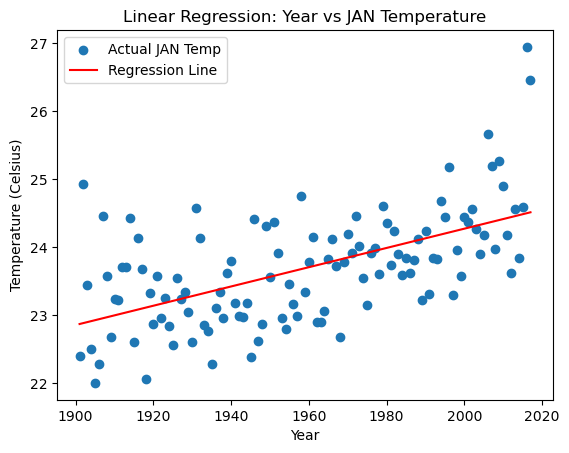

In [2]:
# 1. temperature
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Load dataset
df = pd.read_csv('temperatures.csv')

# Features (Year) and Targets (All 12 Months)
X = df[['YEAR']]
y = df.loc[:, 'JAN':'DEC']

# I. Train Linear Regression & Predict for inputted year
model = LinearRegression()
model.fit(X, y)

year = int(input("Enter Year to predict: "))
pred_year = model.predict([[year]])
print(f"\nPredicted Month-wise Temperatures for {year}:")
print(pd.Series(pred_year[0], index=y.columns))

# II. Assess performance using MSE and MAE
y_pred = model.predict(X)
print("\nMSE:", mean_squared_error(y, y_pred))
print("MAE:", mean_absolute_error(y, y_pred))

# III. Visualize Simple Regression Model (for JAN)
plt.scatter(X, df['JAN'], label='Actual JAN Temp')
plt.plot(X, y_pred[:, 0], color='red', label='Regression Line')
plt.xlabel('Year')
plt.ylabel('Temperature (Celsius)')
plt.title('Linear Regression: Year vs JAN Temperature')
plt.legend()
plt.show()

Missing Values:
 PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


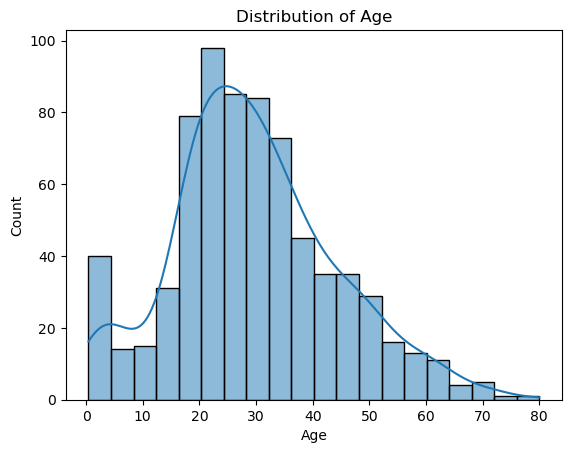

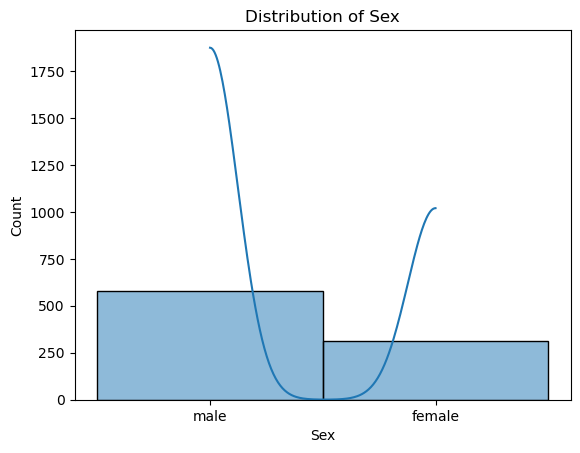

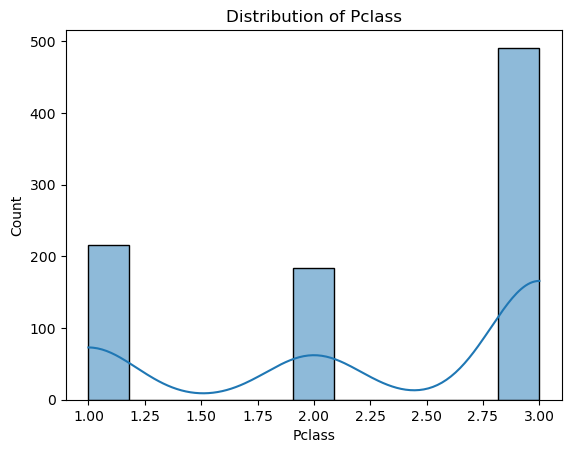

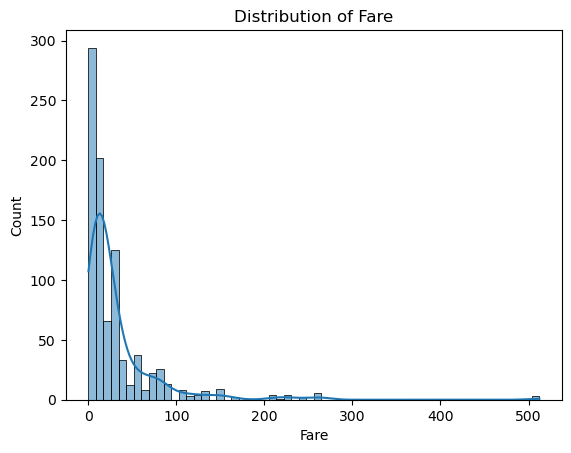

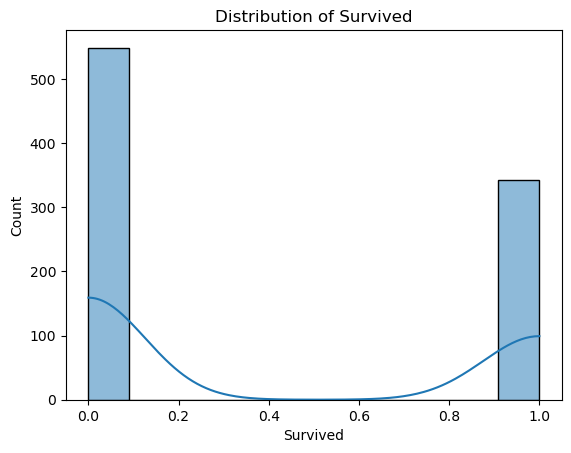

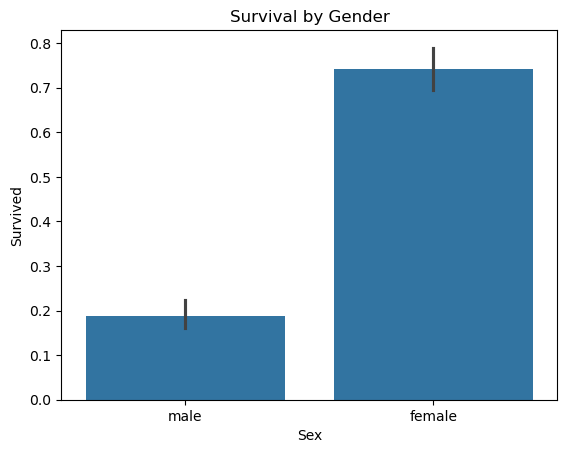

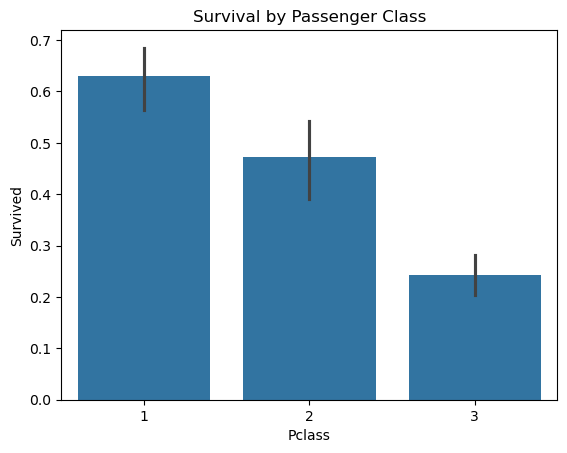

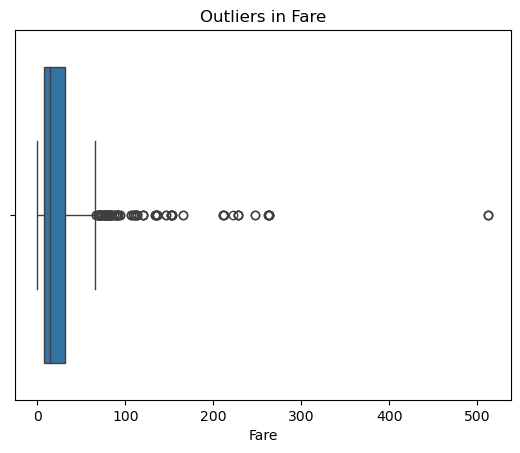

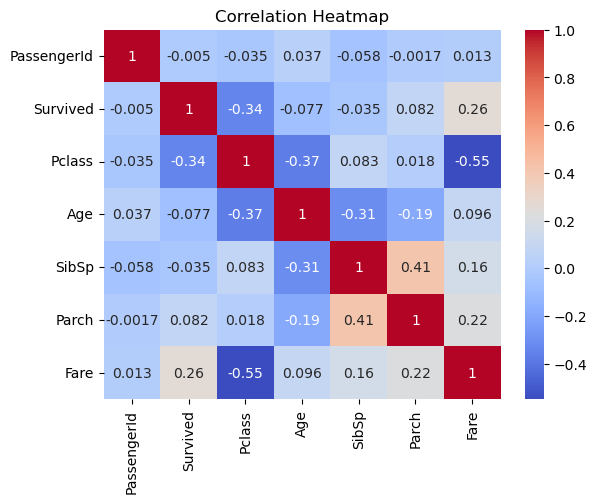

/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


Predicted Survival Probability: 0.93


In [3]:
# 2. Titanic
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

# 1. Load data & identify missing values
df = pd.read_csv('titanic.csv')
print("Missing Values:\n", df.isnull().sum())

# 2. Analyze distributions (Age, Sex, Pclass, Fare, Survived)
for col in ['Age', 'Sex', 'Pclass', 'Fare', 'Survived']:
    sns.histplot(df[col].dropna(), kde=True)
    plt.title(f'Distribution of {col}')
    plt.show()

# 3. Relationship between Survival and Passenger Characteristics
sns.barplot(x='Sex', y='Survived', data=df)
plt.title('Survival by Gender')
plt.show()

sns.barplot(x='Pclass', y='Survived', data=df)
plt.title('Survival by Passenger Class')
plt.show()

# 4. Outliers & Correlation Heatmap
sns.boxplot(x=df['Fare'])
plt.title('Outliers in Fare')
plt.show()

sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

# 5. Predict Probability of Survival (Sex, Age, Pclass)
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})

X = df[['Sex', 'Age', 'Pclass']]
y = df['Survived']

model = LogisticRegression()
model.fit(X, y)

# Example: Female (1), Age 25, Class 1
prob = model.predict_proba([[1, 25, 1]])[0][1]
print(f"Predicted Survival Probability: {prob:.2f}")

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.1 KB
None
       CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000              200.000000
mean   100.500000   38.850000           60.560000               50.200000
std     57.879185   13.969007           26.264721               25.823522
min      1.000000   18.000000           15.000000                1.000000
25%     50.750000   28.750000           41.500000               34.750000
50%    100.500000   36.000000           61.500000      

/lib/python3.14/site-packages/threadpoolctl.py:1135: RuntimeWarning: JsProxy.as_object_map() is deprecated. Use as_py_json() instead.
  for filepath in LDSO.loadedLibsByName.as_object_map():


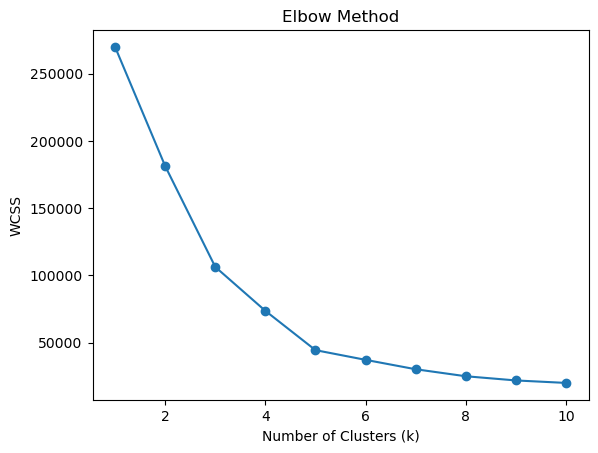

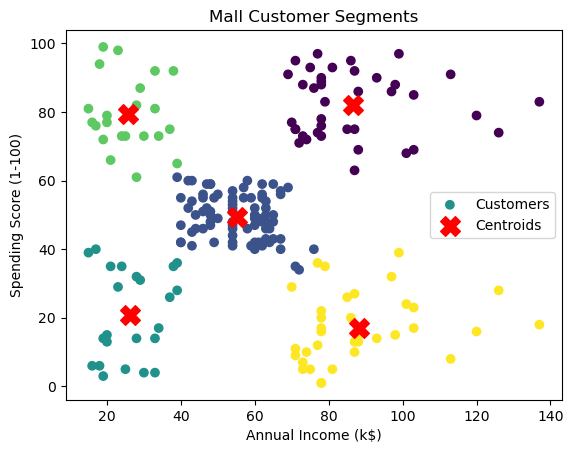


Cluster Interpretation:
- Low Income, Low Spend: Cautious customers (offer basic discounts)
- Low Income, High Spend: Impulsive buyers (offer small-ticket promos)
- Mid Income, Mid Spend: Average customers (standard loyalty programs)
- High Income, Low Spend: Careful savers (promote high-value quality items)
- High Income, High Spend: VIP targets (promote luxury/exclusive products)



In [4]:
# 3. KMeans
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# 1. Load dataset & Exploratory Analysis
df = pd.read_csv('Mall_Customers.csv')
print(df.info())
print(df.describe())

# Select Annual Income (col 3) and Spending Score (col 4)
X = df.iloc[:, [3, 4]].values

# 2. Elbow Method to find optimal K
wcss = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS')
plt.title('Elbow Method')
plt.show()

# 3. Apply K-Means (k=5) & Visualize Clusters with Centroids
kmeans = KMeans(n_clusters=5, n_init=10, random_state=432)
y_kmeans = kmeans.fit_predict(X)

plt.scatter(X[:, 0], X[:, 1], c=y_kmeans, cmap='viridis', label='Customers')
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], 
            s=200, c='red', marker='X', label='Centroids')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Mall Customer Segments')
plt.legend()
plt.show()

# 4. Interpretation for Targeted Marketing
print("""
Cluster Interpretation:
- Low Income, Low Spend: Cautious customers (offer basic discounts)
- Low Income, High Spend: Impulsive buyers (offer small-ticket promos)
- Mid Income, Mid Spend: Average customers (standard loyalty programs)
- High Income, Low Spend: Careful savers (promote high-value quality items)
- High Income, High Spend: VIP targets (promote luxury/exclusive products)
""")

In [5]:
# 4+5. Logic Gates

import numpy as np
from sklearn.neural_network import MLPClassifier

# Input data
X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

# Outputs for logic gates
gates = {
    "AND":  [0, 0, 0, 1],
    "NAND": [1, 1, 1, 0],
    "OR":   [0, 1, 1, 1],
    "NOR":  [1, 0, 0, 0],
    "XOR":  [0, 1, 1, 0]
}

# Create and train neural network
def train_model(Y):

    model = MLPClassifier(
        hidden_layer_sizes=(4,),
        activation='logistic',
        solver='lbfgs',
        max_iter=2000,
        random_state=42
    )

    model.fit(X, Y)
    return model


# Train and predict all gates
for name, Y in gates.items():

    model = train_model(Y)

    print("\n", name, "Gate:")
    print("Predicted Output:", model.predict(X))



 AND Gate:
Predicted Output: [0 0 0 1]

 NAND Gate:
Predicted Output: [1 1 1 0]

 OR Gate:
Predicted Output: [0 1 1 1]

 NOR Gate:
Predicted Output: [1 0 0 0]

 XOR Gate:
Predicted Output: [0 1 1 0]


Highest Close: 309.07000732421875 on 2022-09-19
Lowest Close : 108.0999984741211 on 2023-01-03

Top 10 Highest Daily Gain Days:
          Date       Close  Pct_Change
104 2023-01-27  177.899994   11.000180
103 2023-01-26  160.270004   10.967259
85  2022-12-29  121.820000    8.082691
61  2022-11-23  183.199997    7.821784
140 2023-03-21  197.580002    7.819919
100 2023-01-23  143.750000    7.742469
65  2022-11-30  194.699997    7.670185
116 2023-02-14  209.250000    7.506166
96  2023-01-17  131.490005    7.426474
52  2022-11-10  190.720001    7.393437


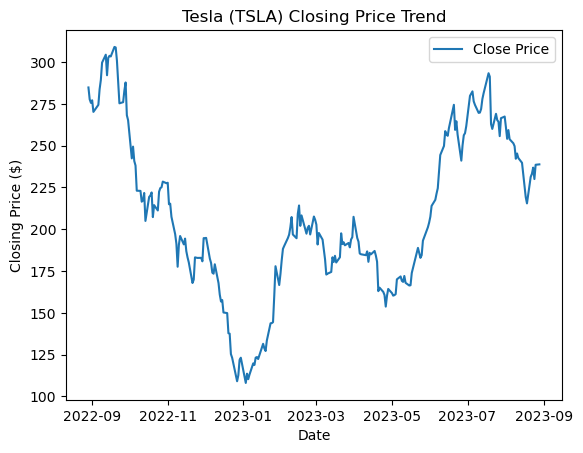

In [6]:
# 6. Tesla Share
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv('TSLA.csv')
df['Date'] = pd.to_datetime(df['Date'])

# 1. Highest and Lowest closing prices & their dates
max_row = df.loc[df['Close'].idxmax()]
min_row = df.loc[df['Close'].idxmin()]
print(f"Highest Close: {max_row['Close']} on {max_row['Date'].date()}")
print(f"Lowest Close : {min_row['Close']} on {min_row['Date'].date()}")

# 2. Daily percentage change in closing price
df['Pct_Change'] = df['Close'].pct_change() * 100

# 3. Top 10 days with highest daily gain
print("\nTop 10 Highest Daily Gain Days:")
print(df[['Date', 'Close', 'Pct_Change']].nlargest(10, 'Pct_Change'))

# 4. Plot Closing-Price Trend
plt.plot(df['Date'], df['Close'], label='Close Price')
plt.xlabel('Date')
plt.ylabel('Closing Price ($)')
plt.title('Tesla (TSLA) Closing Price Trend')
plt.legend()
plt.show()

      Hours_Studied  Attendance  Exam_Score
2726             26          97          73
1260             23          71          67
674              12          80          60
634              14          81          63
3109              9         100          66
Mean    : 65.9
Median  : 66.0
Variance: 12.713793103448275
Std Dev : 3.5656406301600665
Correlation: 0.6400902349012577


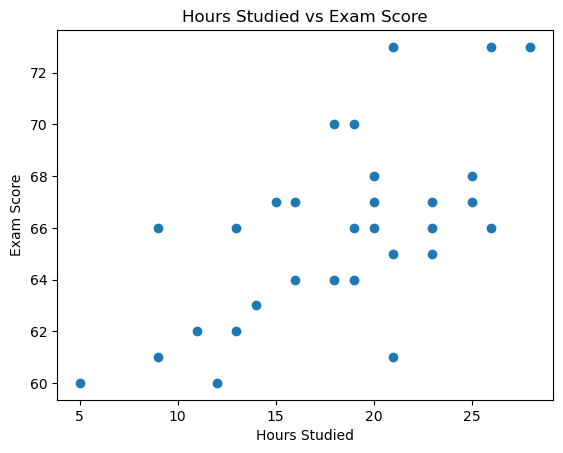

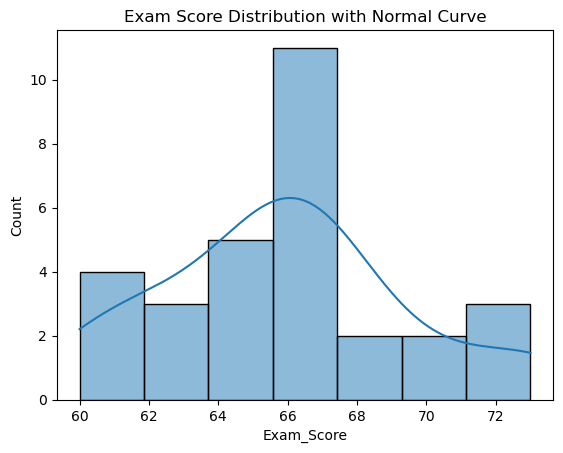

Interpretation: Positive correlation shows more study hours lead to higher exam scores. The bell-shaped curve indicates marks are approximately normally distributed.


In [7]:
# 7. Student Data
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load first 30 students showing required columns
df = pd.read_csv('StudentPerformanceFactors.csv').sample(n=30, random_state=100)
print(df[['Hours_Studied', 'Attendance', 'Exam_Score']].head())

# 1. Mean, Median, Variance, Standard Deviation of Exam_Score
print("Mean    :", df['Exam_Score'].mean())
print("Median  :", df['Exam_Score'].median())
print("Variance:", df['Exam_Score'].var())
print("Std Dev :", df['Exam_Score'].std())

# 2. Correlation between Hours_Studied and Exam_Score
print("Correlation:", df['Hours_Studied'].corr(df['Exam_Score']))

# 3. Scatter Plot
plt.scatter(df['Hours_Studied'], df['Exam_Score'])
plt.xlabel('Hours Studied')
plt.ylabel('Exam Score')
plt.title('Hours Studied vs Exam Score')
plt.show()

# 4. Histogram with Normal Distribution Curve
sns.histplot(df['Exam_Score'], kde=True)
plt.title('Exam Score Distribution with Normal Curve')
plt.show()

# 5. Interpretation
print("Interpretation: Positive correlation shows more study hours lead to higher exam scores. The bell-shaped curve indicates marks are approximately normally distributed.")

      price  area  bedrooms
0  13300000  7420         4
1  12250000  8960         4
2  12250000  9960         3
3  12215000  7500         4
4  11410000  7420         4
Mean    : 4766729.247706422
Median  : 4340000.0
Variance: 3498544355820.573
Std Dev : 1870439.6156573922
Correlation: 0.5359973457780788


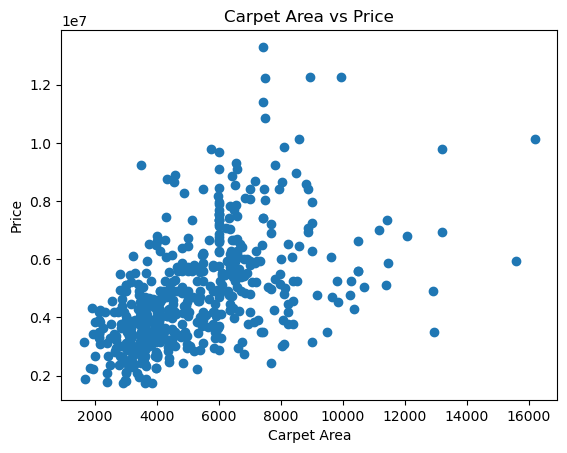

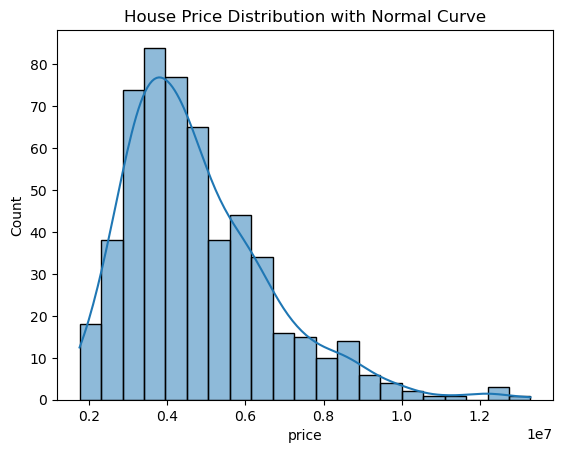

Interpretation: Positive correlation confirms larger carpet area leads to higher house prices. The histogram with KDE curve shows whether prices are approximately normally distributed.


In [8]:
# 8. Housing data
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load first 50 houses showing required columns
df = pd.read_csv('housing.csv')
print(df[['price', 'area', 'bedrooms']].head())

# 1. Mean, Median, Variance, Standard Deviation of price
print("Mean    :", df['price'].mean())
print("Median  :", df['price'].median())
print("Variance:", df['price'].var())
print("Std Dev :", df['price'].std())

# 2. Correlation between area and price
print("Correlation:", df['area'].corr(df['price']))

# 3. Scatter Plot
plt.scatter(df['area'], df['price'])
plt.xlabel('Carpet Area')
plt.ylabel('Price')
plt.title('Carpet Area vs Price')
plt.show()

# 4. Histogram with Normal Distribution Curve
sns.histplot(df['price'], kde=True)
plt.title('House Price Distribution with Normal Curve')
plt.show()

# 5. Interpretation
print("Interpretation: Positive correlation confirms larger carpet area leads to higher house prices. The histogram with KDE curve shows whether prices are approximately normally distributed.")

               Open          High           Low         Close        Volume
count  13647.000000  13647.000000  13647.000000  13647.000000  1.364700e+04
mean     101.096760    102.600108     99.599301    101.096959  2.563550e+06
std      101.152616    101.177291    101.162439    101.159203  1.404601e+06
min      -57.993581    -56.565948    -60.262371    -58.538240  1.003100e+05
25%       16.763759     18.101178     15.121420     16.711654  1.356426e+06
50%       75.232057     76.765118     73.833890     75.271538  2.550567e+06
75%      171.281978    172.948561    169.665120    171.278812  3.779358e+06
max      322.996012    323.769348    320.949858    323.622138  4.999938e+06

Market Sentiment Counts:
 Sentiment
 0.058089    1
 0.751219    1
 0.979723    1
-0.858008    1
 0.264456    1
            ..
 0.038068    1
 0.115523    1
 0.636065    1
-0.143514    1
-0.568854    1
Name: count, Length: 13647, dtype: int64

Highest Close: 323.62213782369884 on 2024-04-08
Lowest Close : -58.53823

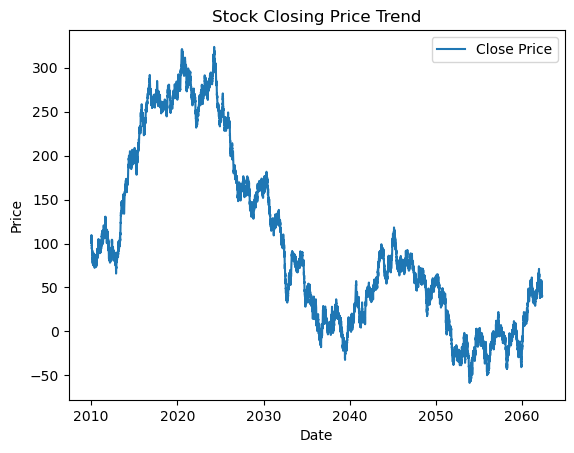

In [9]:
# 9. Stock Market
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv('stock_market_data_large.csv')
df['Date'] = pd.to_datetime(df['Date'])

# 1. Summary Statistics & Sentiment Breakdown
print(df[['Open', 'High', 'Low', 'Close', 'Volume']].describe())
print("\nMarket Sentiment Counts:\n", df['Sentiment'].value_counts())

# 2. Highest and Lowest Closing Prices (Exact same code as Exp 6)
max_row = df.loc[df['Close'].idxmax()]
min_row = df.loc[df['Close'].idxmin()]
print(f"\nHighest Close: {max_row['Close']} on {max_row['Date'].date()}")
print(f"Lowest Close : {min_row['Close']} on {min_row['Date'].date()}")

# 3. Plot Closing Price Trend
plt.plot(df['Date'], df['Close'], label='Close Price')
plt.xlabel('Date')
plt.ylabel('Price')
plt.title('Stock Closing Price Trend')
plt.legend()
plt.show()
